In [56]:
import uproot
import pandas
import numpy as np
import os

import matplotlib.pyplot as plt

uproot.__version__

'5.0.8'

['siliconKINDEX_100nm_Pierce.txt', 'siliconRINDEX_100nm_Pierce.txt', 'lpfilter_500nm.txt', 'sio2_KINDEX_fusedQuartz_uv_web.txt', 'sio2-fusedQuartz_uv_web.txt', 'sio2_INDEX_fusedQuartz_uv_web.txt']


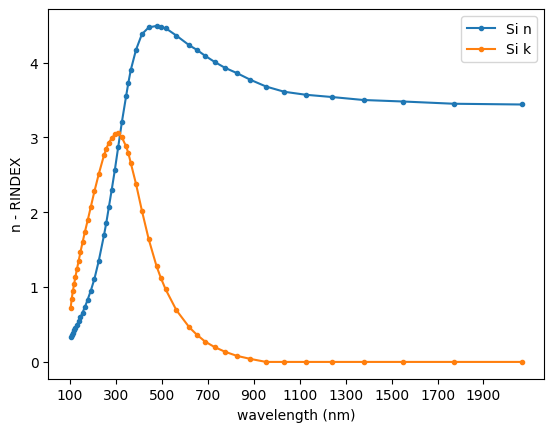

In [79]:

# Define the folder path
folder_path = "../g4PDEsim/dataOptics/"

# Get all .txt files in the folder
file_names = [file for file in os.listdir(folder_path) if file.endswith(".txt")]

# List of entries to remove
entries_to_remove = ["file1.txt", "file2.txt"]

print(file_names)
siX, siY = np.loadtxt(os.path.join(folder_path, "siliconRINDEX_100nm_Pierce.txt"), skiprows=1, unpack = True)
siX *= 1000
sikX, sikY = np.loadtxt(os.path.join(folder_path, "siliconKINDEX_100nm_Pierce.txt"), skiprows=1, unpack = True)
sikX *= 1000



# # Plot each file
# for file_name in file_names:
#   # Load data from the file
#   data = np.loadtxt(os.path.join(folder_path, file_name), skiprows=1)
#   x = data[:, 0]
#   y = data[:, 1]
  
#   # Plot the data
#   plt.plot(x, y, label=file_name)

# Add labels and legend
plt.plot(siX, siY, marker=".", label="Si n")
plt.plot(sikX, sikY, marker=".", label="Si k")
plt.xlabel("wavelength (nm)")
plt.ylabel("n - RINDEX")
plt.legend()

# Set the x tick labels
plt.xticks(np.arange(100, max(siX)+1, 200))


# Show the plot
plt.show()


In [82]:
fileAir = uproot.open("air_N1e5_200-1200nm_0-60deg.root")
fileCF4 = uproot.open("lcf4_N1e5_200-1200nm_0-60deg.root")

ttAir = fileAir["simOutput"]
ttcf4 = fileCF4["simOutput"]


# Define the column names
column_names = ["fNphoton", "fPhotonWln", "fAngle", "fNonWindow", "fNonSurface", "fNonBulk", "fNinBulk"]
dfair = ttAir.arrays(library="pd")
print(dfair.head(5))
dfair["fin"] = dfair["fNinBulk"]/dfair["fNphoton"]

dfcf4 = ttcf4.arrays(library="pd")
dfcf4["fin"] = dfcf4["fNinBulk"]/dfcf4["fNphoton"]

# print(type(df))
# print(df.columns)

angles = dfair['fAngle'].unique()
print(angles)


   fNphoton  fPhotonWln     fAngle  fNonWindow  fNonSurface  fNonBulk   
0     10000  199.974514   0.000000         110           56        14  \
1     10000  199.974514  33.600021         120           67        32   
2     10000  199.974514  48.200017         216           90        35   
3     10000  199.974514  60.000140         481          229        61   
4     10000  210.142709   0.000000         873          366       155   

   fNinBulk  
0      9820  
1      9781  
2      9659  
3      9229  
4      8606  
[ 0.         33.60002128 48.20001722 60.00014031]


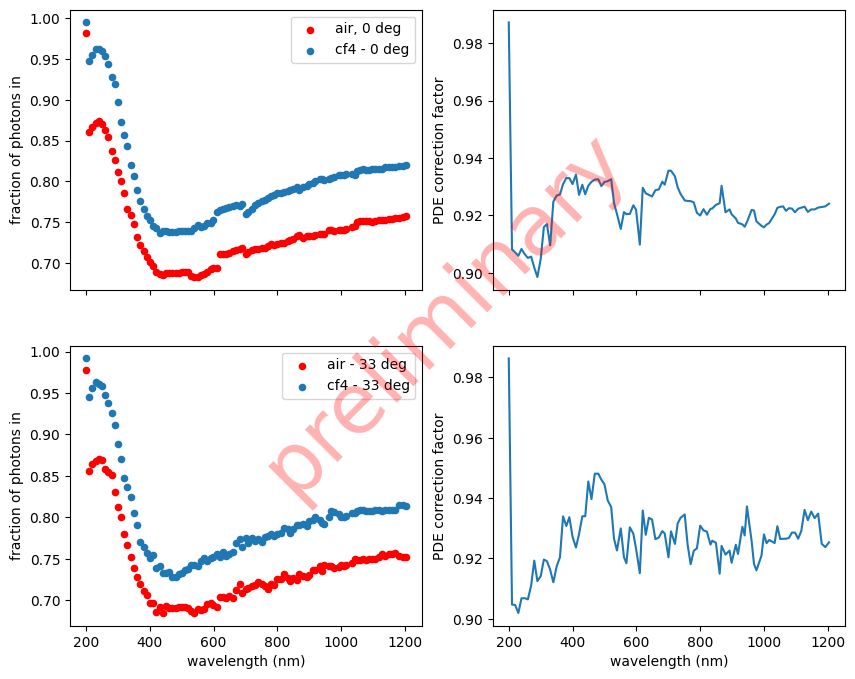

In [116]:

dfAir_a0 = dfair[dfair["fAngle"] == angles[0]]
dfcf4_a0 = dfcf4[dfcf4["fAngle"] == angles[0]]

dfAir_a33 = dfair[dfair["fAngle"] == angles[1]]
dfcf4_a33 = dfcf4[dfcf4["fAngle"] == angles[1]]

# Plot the data frames on the same canvas
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, sharex='all', figsize=(10, 8))

dfAir_a0.plot(x="fPhotonWln", y="fin", kind="scatter", color='r', label='air, 0 deg', ax = ax1)
dfcf4_a0.plot(x="fPhotonWln", y="fin", kind="scatter", label="cf4 - 0 deg", ax = ax1)

ax2.plot(dfAir_a0["fPhotonWln"], dfAir_a0["fin"]/dfcf4_a0["fin"], label="air/cf4 - 0 deg")

dfAir_a33.plot(x="fPhotonWln", y="fin", kind="scatter", color='r', label='air - 33 deg', ax = ax3)
dfcf4_a33.plot(x="fPhotonWln", y="fin", kind="scatter", label="cf4 - 33 deg", ax = ax3)
ax4.plot(dfAir_a33["fPhotonWln"], dfAir_a33["fin"]/dfcf4_a33["fin"], label="air/cf4 - 33 deg")

ax1.set_ylabel("fraction of photons in")
ax3.set_ylabel("fraction of photons in")
ax1.set_xlabel("wavelength (nm)")
ax3.set_xlabel("wavelength (nm)")

ax2.set_ylabel("PDE correction factor")
ax4.set_ylabel("PDE correction factor")
ax2.set_xlabel("wavelength (nm)")
ax4.set_xlabel("wavelength (nm)")

# Add "preliminary" text at 45 degrees
fig.text(0.5, 0.5, "preliminary", color='red', alpha=0.3, rotation=45, ha='center', va='center', fontsize=60)

# Adjust the spacing between subplots
# plt.tight_layout()

# Show the plot
plt.show()


In [ ]:
print(type(tt))
print(tt.keys())
np = tt.arrays("fNphoton")
tt.num_entries